### Отчет 
Билалова Ильнара

Для обучения модели было выбрано 4 класса:

Яблоки, Бананы, Ананасы, Прочее

Точность модели:

* Яблоки: Точность 0.80.

* Бананы: Точность 0.75.

* Ананасы: Точность 0.75. 

* Прочее: Точность 0.75. 

Модель была проверена на 17 изображениях, распределенных по 4 классам.

Наилучший результат показал класс «Яблоки» - точность 0.80. Из 5 изображений модель верно определила 4, однако одно яблоко было ошибочно отнесено к категории «Прочее».

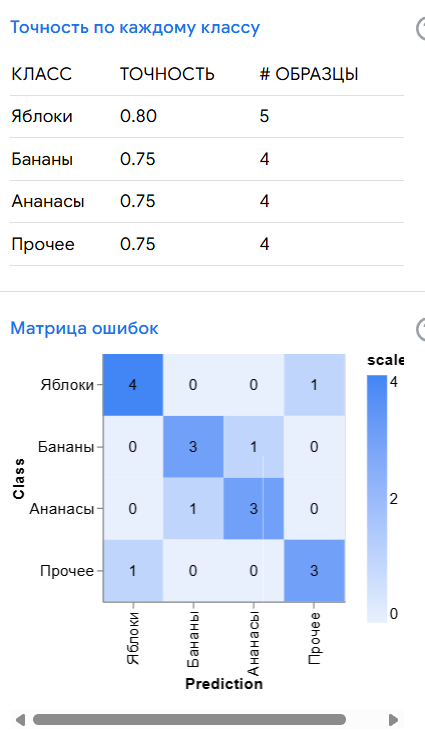


#### Модель показала среднюю точность на каждый класс. Лучше всего она распознает яблоки (80%), а бананы, ананасы и класс «Прочее» - по 75%.

#### Проверка модели на новых предметах:

Банан - модель уверенно распознала его как «Банан» с вероятностью 95%.

Кожура от банана - также правильно классифицирована как «Банан» с уверенностью 98% (модель хорошо определяет признаки объекта, несмотря на изменение его формы).

Яблоко - распознано как «Яблоко» с уверенностью 90%.

Ананас - распознан как «Ананас» с уверенностью 100%.

Проверка на предметах из категории «Прочее»:

Свекла - модель отнесла к классу «Прочее» со 100% уверенностью.

Морковь - отнесена к классу «Прочее» с уверенностью 94%.


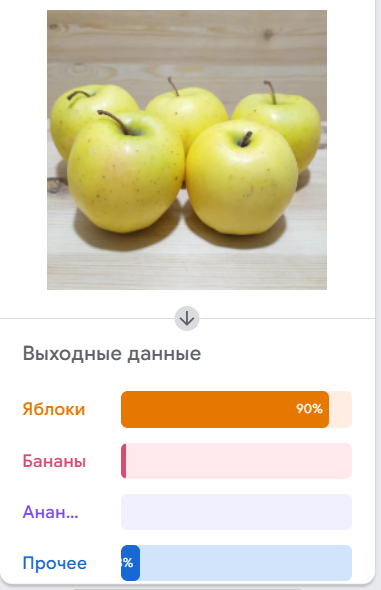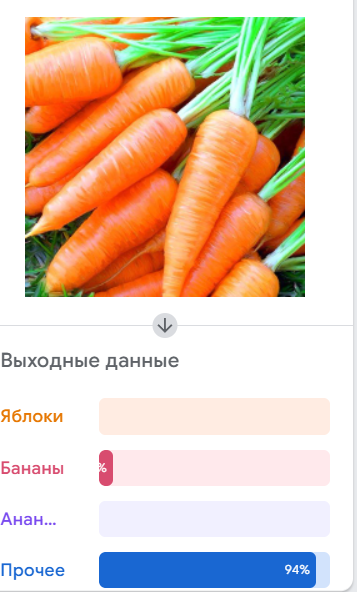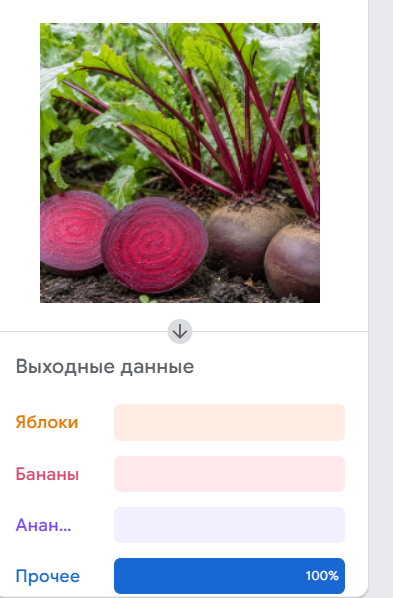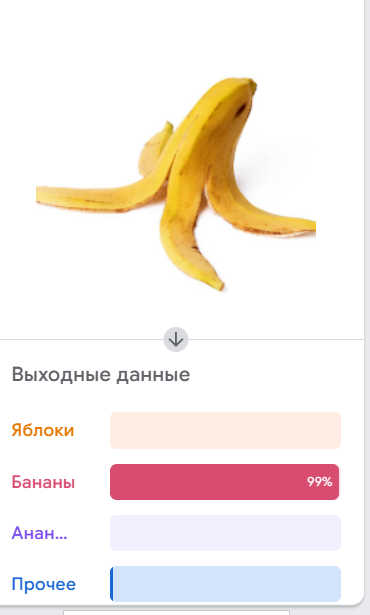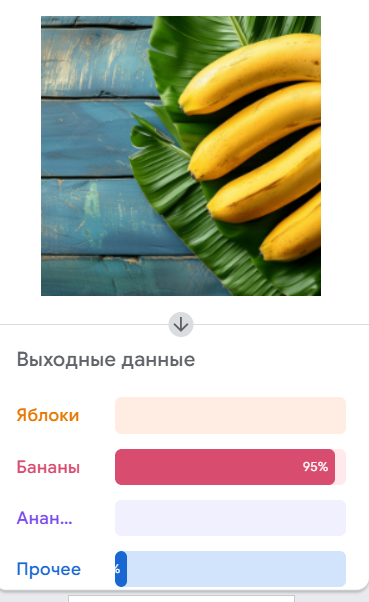 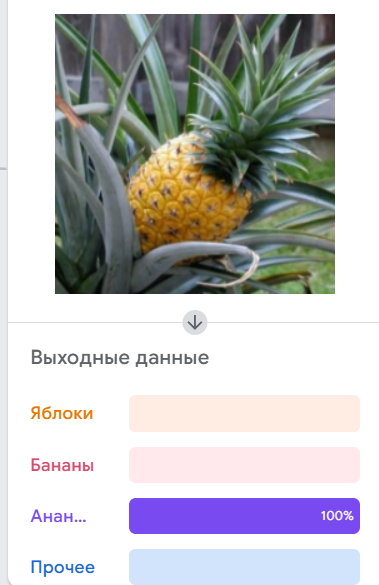

In [6]:
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np
import os

model_path = r"C:\Users\ilnar\Downloads\FructiMachine\converted_keras (1)\keras_model.h5"
labels_path = r"C:\Users\ilnar\Downloads\FructiMachine\converted_keras (1)\labels.txt"

model = load_model(model_path, compile=False)
class_names = open(labels_path, "r", encoding="utf-8").readlines()

folder_paths = [
    r"C:\Users\ilnar\OneDrive\Рабочий стол\Яблоки тест",
    r"C:\Users\ilnar\OneDrive\Рабочий стол\Ананасы тест",
    r"C:\Users\ilnar\OneDrive\Рабочий стол\Тест",
    r"C:\Users\ilnar\OneDrive\Рабочий стол\Бананы тест"
]

for folder_path in folder_paths:
    if not os.path.exists(folder_path):
        print(f"Папка не найдена: {folder_path}")
        continue
        
    print(f"\n Проверяем папку: {os.path.basename(folder_path)}")
    
    files = os.listdir(folder_path)
    
    for file_name in files:
        if file_name.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_path = os.path.join(folder_path, file_name)
            
            data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
            image = Image.open(image_path).convert("RGB")
            size = (224, 224)
            image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
            image_array = np.asarray(image)
            normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
            data[0] = normalized_image_array

            # Предсказание
            prediction = model.predict(data, verbose=0)
            index = np.argmax(prediction)
            class_name = class_names[index][2:].strip() 
            confidence_score = prediction[0][index]

            print(f"Файл: {file_name} - Класс: {class_name} (Уверенность: {round(float(confidence_score), 3)})")


 Проверяем папку: Яблоки тест
Файл: 07ee568cb63cae08fe22dc1adc3240f9.jpg - Класс: Яблоки (Уверенность: 0.977)
Файл: 631affab0c663549390f7bdaed35e849.jpg - Класс: Яблоки (Уверенность: 0.679)
Файл: 803a82023e7cc52a7a9e01c03fe4cf0b.jpg - Класс: Яблоки (Уверенность: 0.987)
Файл: be4f0004ef9ef32084b9f632e6d52b27.jpg - Класс: Прочее (Уверенность: 0.797)
Файл: front-view-yellow-apples-checkered-tablecloth-table_141793-6841.jpg - Класс: Яблоки (Уверенность: 0.924)
Файл: qhgardiwhyzteia6hxfom5rmmchepyv1.jpg - Класс: Яблоки (Уверенность: 0.974)

 Проверяем папку: Ананасы тест
Файл: 1eb615e6-192f-4e74-9e25-92b573c70f29_0.jpg - Класс: Ананасы (Уверенность: 0.964)
Файл: ee55aeaa473136bec67e57b679743756.jpg - Класс: Ананасы (Уверенность: 0.98)
Файл: istockphoto-1472928506-1024x1024.jpg - Класс: Ананасы (Уверенность: 0.998)
Файл: owl_wide_1200_2e89764dfd4dc56b47a2588565143b21.jpg - Класс: Ананасы (Уверенность: 0.999)
Файл: ананас-19113450.jpg - Класс: Ананасы (Уверенность: 0.999)
Файл: ананас-и-и-ан

### Вывод
Модель отлично справляется с распознаванием своих основных классов (бананы, яблоки, ананасы). Ошибки возникают в основном на сложных или посторонних предметах, которые не похожи на обучающую выборку.

## Задание 3.

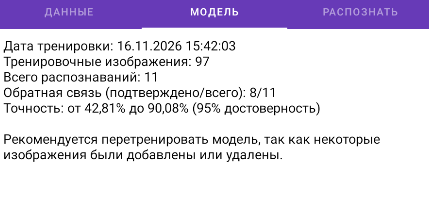

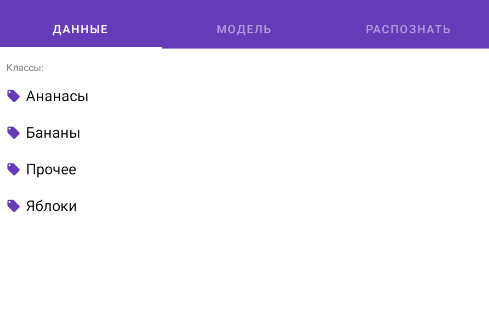 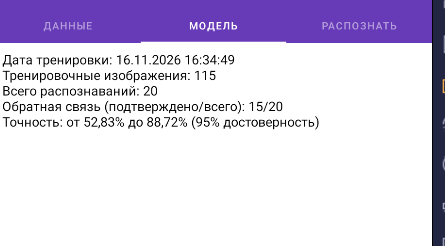 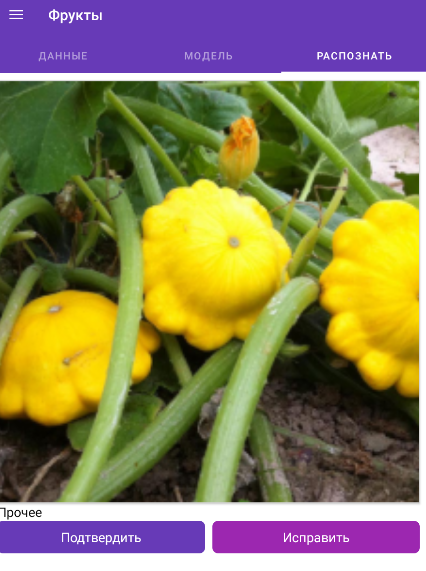  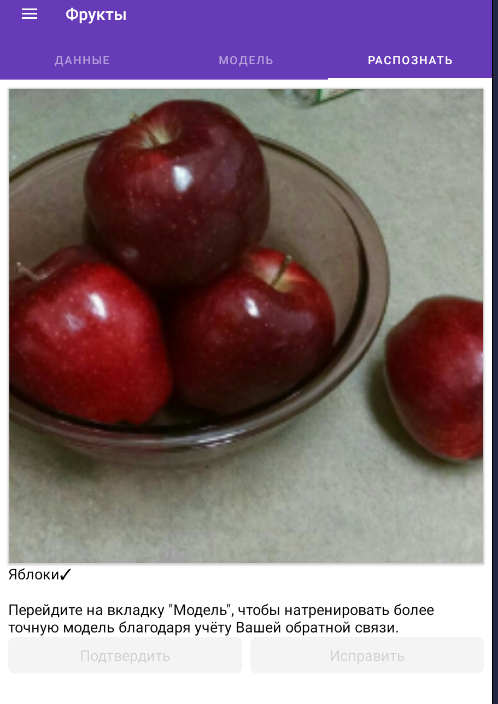

Модель в Pocket AutoML обучена распознавать фрукты. После  тренировки точность была 52–88%.
Я провел тестирование и подтвердил/исправил результаты (15 из 20). После этого модель стала работать точнее.

## Задание 4.

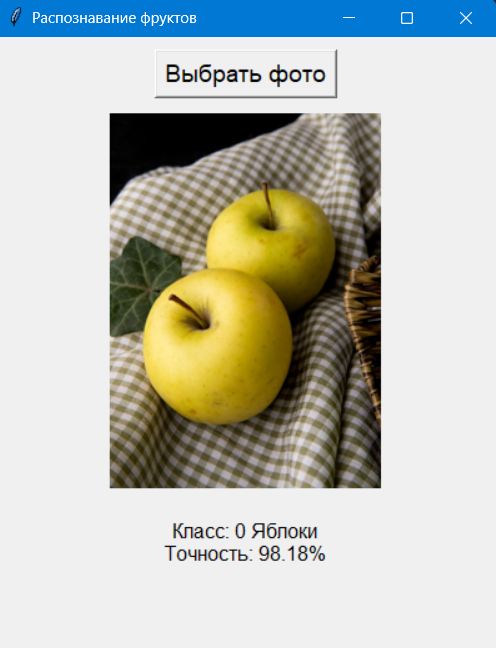 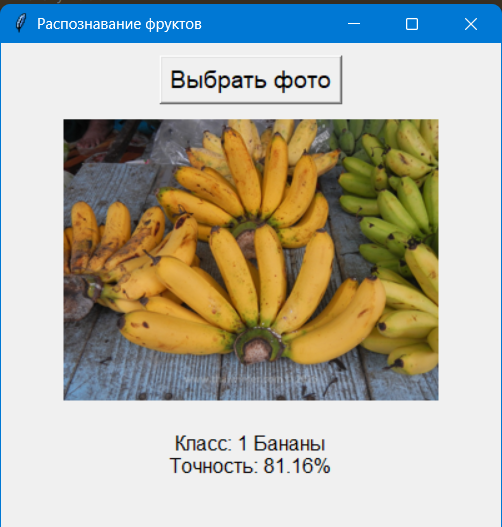


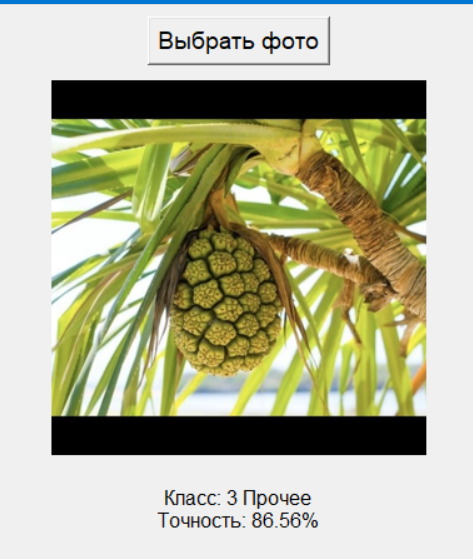 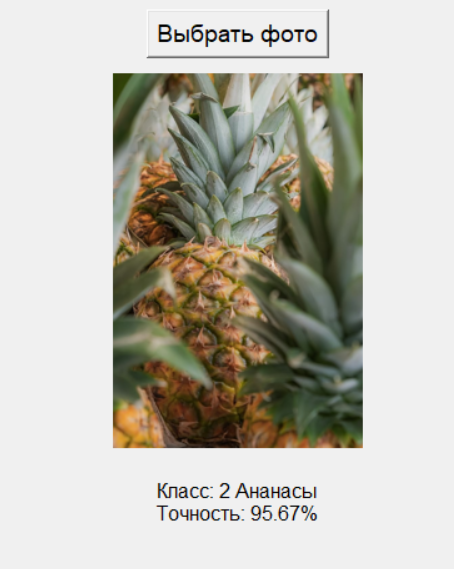

### Вывод: модель хорошо различает похожие на друг друга фрукты по своим классам.